# Progetto: Modello per la Classificazione di Contenuti Testuali Aziendali

### di Lavinia Solimani

Per questo progetto, il task da affrontare è lo sviluppo di un modello AI basato sul Natural Language Processing (NLP) per identificare e classificare automaticamente i diversi tipi di contenuti aziendali, migliorando l'organizzazione e l'accessibilità delle informazioni.

Il progetto si svilupperà nelle seguenti tre fasi.

1. **Raccolta e annotazione dati**: creazione di un dataset etichettato con diverse tipologie di documenti. In questa fase eseguiremo la pre-elaborazione del testo;
2. **Addestramento del modello NLP**: sviluppo, addestramento e tuning di un modello di classificazione per riconoscere categorie di documenti;
3. **Integrazione e testing**: valutazione dei risultati e applicazione del modello su documenti in ingresso per nuove classificazioni.

In [ ]:
%%capture
!pip install --upgrade pandas -q

In [ ]:
# No warnings
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [ ]:
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import unicodedata
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
# Seed for reproducibility
RANDOM_SEED = 42

# Device: GPU if available, else CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device currently in use: {device}')

# Figure style
sns.set_theme(style = 'whitegrid')

Device currently in use: cpu


## 1. Raccolta e annotazione dati

### 1.1 Caricamento e analisi esplorativa del dataset

Per questo task, abbiamo generato un dataset fittizio in formato CSV contenente 10.000 documenti aziendali, suddivisi nelle seguenti cinque categorie:

1. **Financial Reports**: Bilanci, audit di contabilità, proiezioni di ricavi e variazioni dei margini di profitto.
2. **Legal Contracts**: Accordi di riservatezza (NDA), contratti di servizio (SLA) e clausole di indennizzo.
3. **HR & Internal Policies**: Regolamenti aziendali, gestione delle ferie, rimborsi spese e welfare dei dipendenti.
4. **IT & Security Notices**: Avvisi di manutenzione del sistema e aggiornamenti delle policy di sicurezza informatica.
5. **Customer Support**: Escalation di reclami, errori di fatturazione e richieste formali di rimborso.

In [ ]:
df = pd.read_csv('corporate_documents.csv', sep = ',', index_col = 0)
df.head(10)

,text,label,word_count
id,,,
1,The current estimate was compared with the pre...,Financial Reports,939
2,The immediate workaround was kept separate fro...,Legal Contracts,982
3,The proposed text is intended to clarify the p...,Customer Support,381
4,One section was revised because the same term ...,Customer Support,780
5,An earlier version of the plan was retained so...,Financial Reports,1103
6,A validation step was added before the previou...,IT & Security Notices,678
7,A question about timing was left open because ...,IT & Security Notices,707
8,The evidence is enough for the immediate actio...,Legal Contracts,1237
9,One section was revised because the same term ...,Financial Reports,639


In [ ]:
print('Dataset shape:', df.shape)

Dataset shape: (10000, 3)


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 1 to 10000
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text        10000 non-null  str  
 1   label       10000 non-null  str  
 2   word_count  10000 non-null  int64
dtypes: int64(1), str(2)
memory usage: 54.8 MB


In [ ]:
# ================================================
# DATA QUALITY
# ================================================

# Missing values
print('\nMissing values:')
print(df.isna().sum())

# Exact duplicate texts
print('\nExact duplicate texts:', df['text'].duplicated().sum())


Missing values:
text          0
label         0
word_count    0
dtype: int64

Exact duplicate texts: 0


In [ ]:
# ================================================
# LABEL DISTRIBUTION
# ================================================

labels = df['label'].unique()
print(labels)

# Calculate counts and percentages
label_counts = df['label'].value_counts()
report = label_counts.reset_index()
report.columns = ['Label', 'Count']
report['Percentage'] = (report['Count'] / report['Count'].sum() * 100).round(2)
report.style.format({'Percentage': '{:.2f}%'})

<ArrowStringArray>
[     'Financial Reports',        'Legal Contracts',       'Customer Support',
  'IT & Security Notices', 'HR & Internal Policies']
Length: 5, dtype: str


,Label,Count,Percentage
0,Financial Reports,3500,35.00%
1,Legal Contracts,2500,25.00%
2,HR & Internal Policies,2000,20.00%
3,Customer Support,1000,10.00%
4,IT & Security Notices,1000,10.00%


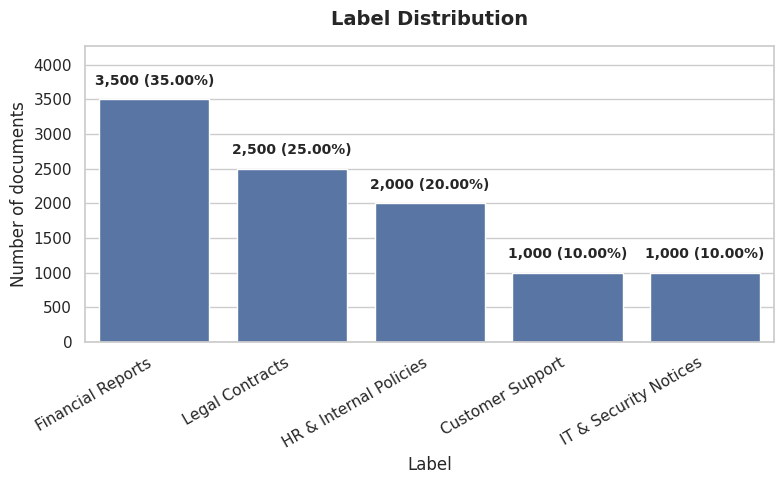

In [ ]:
# Plot label distribution
label_counts = df['label'].value_counts()
percentages = label_counts / label_counts.sum() * 100

plt.figure(figsize = (8, 5))
ax = sns.barplot(x = label_counts.index, y = label_counts.values)

for bar, (count, percentage) in zip(
    ax.patches, zip(label_counts.values, percentages.values)):
    height = bar.get_height()
    ax.annotate(f'{count:,} ({percentage:.2f}%)',
                (bar.get_x() + bar.get_width() / 2, height),
                ha = 'center',
                va = 'bottom',
                xytext = (0, 8),
                textcoords = 'offset points',
                fontsize = 10,
                fontweight = 'bold')

plt.title('Label Distribution', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Label', fontsize = 12)
plt.xticks(rotation = 30, ha = 'right')
plt.ylabel('Number of documents', fontsize = 12)
plt.ylim(0, max(label_counts.values) * 1.22)

plt.tight_layout()
plt.savefig('label_distribution.png')
plt.show()

In [ ]:
# ================================================
# WORD COUNT
# ================================================
print(df['word_count'].describe().round(0))

count    10000.0
mean       858.0
std        225.0
min        374.0
25%        707.0
50%        854.0
75%       1003.0
max       1463.0
Name: word_count, dtype: float64


In [ ]:
word_count_by_label = (
    df.groupby('label')['word_count']
      .agg([
          'count',
          'mean',
          'median',
          'std',
          'min',
          'max'
          ])
          .round(2)
          )

word_count_by_label

,count,mean,median,std,min,max
label,,,,,,
Customer Support,1000,560.83,541.0,142.56,374,1016
Financial Reports,3500,906.23,906.0,148.32,429,1421
HR & Internal Policies,2000,767.46,770.0,125.02,380,1136
IT & Security Notices,1000,659.88,658.0,155.51,378,1132
Legal Contracts,2500,1059.98,1062.0,198.36,380,1463


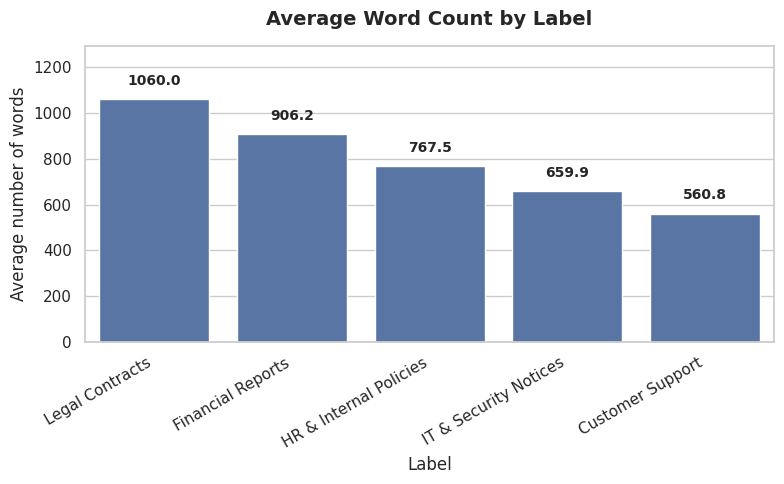

In [ ]:
# Average number of words for each label
word_count_mean = (df.groupby('label')['word_count'].mean().sort_values(ascending = False))

plt.figure(figsize = (8, 5))
ax = sns.barplot(x = word_count_mean.index, y = word_count_mean.values)

for bar, mean in zip(ax.patches, word_count_mean.values):

    height = bar.get_height()

    ax.annotate(f'{mean:.1f}',
                (bar.get_x() + bar.get_width() / 2, height),
                ha = 'center',
                va = 'bottom',
                xytext = (0, 8),
                textcoords = 'offset points',
                fontsize = 10,
                fontweight = 'bold')

plt.title('Average Word Count by Label', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Label', fontsize = 12)
plt.xticks(rotation = 30, ha = 'right')
plt.ylabel('Average number of words', fontsize = 12)
plt.ylim(0, max(word_count_mean.values) * 1.22)

plt.tight_layout()
plt.savefig('avg_word_count.png')
plt.show()

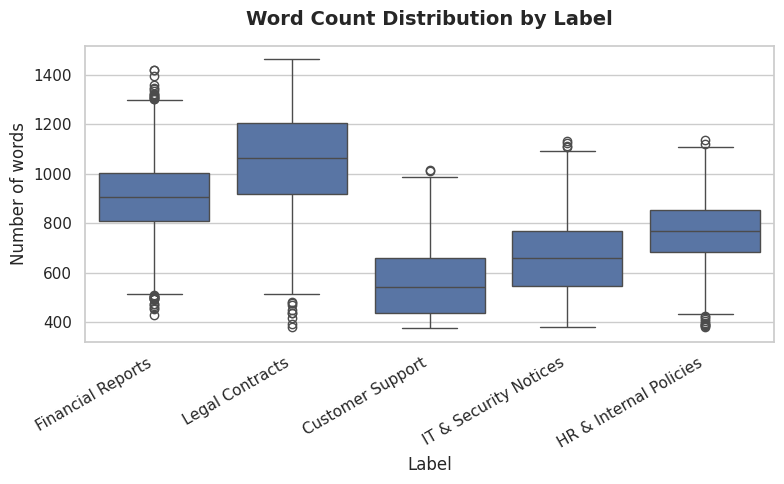

In [ ]:
plt.figure(figsize = (8, 5))
sns.boxplot(data = df, x = 'label', y = 'word_count')
plt.title('Word Count Distribution by Label', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Label', fontsize = 12)
plt.xticks(rotation = 30, ha = 'right')
plt.ylabel('Number of words', fontsize = 12)

plt.tight_layout()
plt.savefig('word_count_distr.png')
plt.show()

Dai due grafici si evince che sia il numero medio di parole nei documenti che la distribuzione sono molto diversi tra le categorie. Per quanto riguarda il numero medio di parole, "Customer Support" ha i documenti più brevi (circa 561 parole in media), mentre "Legal Contracts" ha i documenti più lunghi (circa 1060 parole in media). In merito alla distribuzione, "Financial Reports" e "Legal Contracts" sono le categorie con una maggior varietà nella lunghezza dei documenti, mentre "Customer Support" è la categoria con la minor varietà. Nelle distribuzioni sono inoltre presenti diversi outliers; in alcuni casi gli outliers si trovano nella parte superiore della distribuzione, in altri casi in quella inferiore, e in altri ancora in entrambe.

In [ ]:
# =============================================================
# CHECK FOR MATCH BETWEEN WORD_COUNT AND NUMBER OF WORDS IN TEXT
# =============================================================

# Calculate number of words in all texts
df['calculated_word_count'] = (df['text'].str.split().str.len())

# Comparison with word_count
df['word_count_match'] = (df['word_count'] == df['calculated_word_count'])

print('Number of rows with word_count not matching:',
      (~df['word_count_match']).sum())

Number of rows with word_count not matching: 0


In [ ]:
# =============================================================
# CHECK FOR TEXTS WITH MORE THAN ONE LABEL
# =============================================================

text_multiple_labels = (df.groupby('text')['label'].nunique())
ambiguous_texts = text_multiple_labels[text_multiple_labels > 1]
print('Number of texts with more than one label:', len(ambiguous_texts))

Number of texts with more than one label: 0


### 1.2 Data cleaning

Definiamo una funzione che esegua il **data cleaning**. Non eseguiremo una pulizia aggressiva, in particolare non andremo a rimuovere i numeri, per non rischiare di incorrere in perdita di informazione. Inoltre, non procederemo con stemming o lemmatizzazione.

In [ ]:
# ============================================================
# DATA CLEANING
# ============================================================

def clean_text(text):

  """
  This function performs specific steps of minimal data cleaning
  on structured company documents for text classification.
  """

  # 1. Check if text is a string
  if not isinstance(text, str):
        return ''

  # 2. Convert all to lowercase
  text = text.lower()

  # 3. Normalise unicode
  text = unicodedata.normalize('NFKC', text)

  # 4. Remove URLs and HTML tags
  text = re.sub(r'http\S+|www\S+|https\S+', '', text)
  text = re.sub(r'<.*?>', '', text)

  # 5. Remove extra spaces
  text = re.sub(r'\s+', ' ', text).strip()

  return text



df['text_cleaned'] = df['text'].apply(clean_text)
df[['text', 'text_cleaned']].head(10)

,text,text_cleaned
id,,
1,The current estimate was compared with the pre...,the current estimate was compared with the pre...
2,The immediate workaround was kept separate fro...,the immediate workaround was kept separate fro...
3,The proposed text is intended to clarify the p...,the proposed text is intended to clarify the p...
4,One section was revised because the same term ...,one section was revised because the same term ...
5,An earlier version of the plan was retained so...,an earlier version of the plan was retained so...
6,A validation step was added before the previou...,a validation step was added before the previou...
7,A question about timing was left open because ...,a question about timing was left open because ...
8,The evidence is enough for the immediate actio...,the evidence is enough for the immediate actio...
9,One section was revised because the same term ...,one section was revised because the same term ...


### 1.3 Suddivisione in set di addestramento e di test

Procediamo ora con la suddivisione del dataset in set di addestramento e di test. Per garantire che la distribuzione delle classi venga mantenuta in entrambi i set, passeremo lo **stratify** in fase di split.

In [ ]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X = df['text_cleaned']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2,
                                                    stratify = y, random_state = RANDOM_SEED)

# Check distributions
train_distribution = (y_train.value_counts(normalize = True)
                      .reindex(labels, fill_value = 0)
                      .mul(100)
                      .round(2))
test_distribution = (y_test.value_counts(normalize = True)
                     .reindex(labels, fill_value = 0)
                     .mul(100)
                     .round(2))

print('\nTRAIN SET DISTRIBUTION (%):', train_distribution)
print('\nTEST SET DISTRIBUTION (%):', test_distribution)


TRAIN SET DISTRIBUTION (%): label
Financial Reports         35.0
Legal Contracts           25.0
Customer Support          10.0
IT & Security Notices     10.0
HR & Internal Policies    20.0
Name: proportion, dtype: float64

TEST SET DISTRIBUTION (%): label
Financial Reports         35.0
Legal Contracts           25.0
Customer Support          10.0
IT & Security Notices     10.0
HR & Internal Policies    20.0
Name: proportion, dtype: float64


### 1.4 Cross-validation

Procediamo ora con la cross-validation. Poiché le classi del dataset sono sbilanciate, utilizzeremo la [Stratified K Fold Cross Validation](https://www.geeksforgeeks.org/machine-learning/stratified-k-fold-cross-validation/), in modo che la distribuzione di ciascuna classe sia mantenuta in ogni fold.

In [ ]:
# ============================================================
# CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = RANDOM_SEED)

## 2. Addestramento del modello NLP

### 2.1 Pipeline dei modelli

Per questo task, addestreremo e confronteremo i seguenti modelli:

- Regressione Logistica;
- Linear SVM;
- Multinomial Naive Bayes;
- Multilayer Perceptron.

Procediamo quindi ad istanziare ciascun modello, includendo come primo elemento della pipeline una vettorizzazione con **TF-IDF**. Nel caso del Multilayer Perceptron, per non rendere la successiva grid search troppo dispendiosa a livello computazionale, non utilizzeremo un range troppo vasto di iperparametri.

In [ ]:
# ============================================================
# MODEL PIPELINES
# ============================================================

# -----------------------------
# LOGISTIC REGRESSION
# -----------------------------

log_reg_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', LogisticRegression(
        max_iter = 2000,
        class_weight = 'balanced',
        random_state = RANDOM_SEED))
])


# -----------------------------
# LINEAR SVM
# -----------------------------

svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', LinearSVC(
        class_weight = 'balanced',
        random_state = RANDOM_SEED))
])


# -----------------------------
# MULTINOMIAL NAIVE BAYES
# -----------------------------

mnb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', MultinomialNB())
])


# -----------------------------
# MULTILAYER PERCEPTRON
# -----------------------------

mlp_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        min_df = 3)),
    ('classifier', MLPClassifier(
        hidden_layer_sizes = (50,),
        solver = 'adam',
        batch_size = 128,
        max_iter = 150,
        random_state = RANDOM_SEED))
])


# Define dictionary with all models
models = {
    'Logistic Regression' : log_reg_pipeline,
    'Linear SVM' : svm_pipeline,
    'Multinomial Naive Bayes' : mnb_pipeline,
    'MLPClassifier' : mlp_pipeline
    }

### 2.2 Grid search per tuning degli iperparametri
Per la grid search e la scelta degli iperparametri, utilizzeremo come metrica di osservazione il **macro-F1**. Questa metrica è la media non pesata dell'F1-score di ciascuna classe, quindi considera tutte le categorie allo stesso modo, indipendentemente dalla rappresentazione di ciascuna nel dataset.

In [ ]:
# ============================================================
# GRID SEARCH FOR HYPERPARAMETER TUNING
# ============================================================

log_reg_params = {'tfidf__ngram_range' : [(1, 1), (1, 2)],
                  'tfidf__min_df' : [1, 2, 3],
                  'classifier__C' : [0.1, 1, 10]
                  }

svm_params = {'tfidf__ngram_range' : [(1, 1), (1, 2)],
              'tfidf__min_df' : [1, 2, 3],
              'classifier__C' : [0.1, 1, 10]
              }

mnb_params = {'tfidf__ngram_range' : [(1, 1), (1, 2)],
              'tfidf__min_df' : [1, 2, 3],
              'classifier__alpha' : [0.01, 0.1, 1]
              }

mlp_params = {'tfidf__ngram_range' : [(1, 1), (1, 2)],
              'classifier__activation' : ['relu', 'logistic'],
              'classifier__alpha' : [0.0001, 0.01]
              }


def grid_search(pipeline, param_grid, model_name):

    """
    This function runs a grid search on specific models with given parameters.
    """

    grid = GridSearchCV(estimator = pipeline, param_grid = param_grid,
                        scoring = 'f1_macro', cv = cv, n_jobs = -1
                        )

    grid.fit(X_train, y_train)

    print('\n' + '=' * 80)
    print(model_name)
    print('\n' + '=' * 80)

    print('Best parameters:', grid.best_params_)
    print('Best CV Macro F1:', round(grid.best_score_, 4))

    return grid

### 2.3 Training, confronto e scelta del modello

In [ ]:
# ============================================================
# MODEL TRAINING / LOADING
# ============================================================

MODEL_PATH = 'best_model.pkl'

if os.path.exists(MODEL_PATH):

    # --------------------------------------------------------
    # LOAD EXISTING MODEL
    # --------------------------------------------------------

    print(f'Loading existing model from: {MODEL_PATH}')

    with open(MODEL_PATH, 'rb') as file:
        model_data = pickle.load(file)

    best_model = model_data['model']
    best_model_name = model_data['model_name']
    best_cv_score = model_data['cv_macro_f1']
    best_params = model_data['best_params']
    results = model_data['results']

    print('\nExisting model loaded successfully!')
    print('Best model:', best_model_name)
    print('CV Macro-F1:', round(best_cv_score, 4))
    print('Parameters:', best_params)

else:

    # --------------------------------------------------------
    # HYPERPARAMETER TUNING
    # --------------------------------------------------------

    print('No saved model found. Starting parameter tuning...\n')

    log_reg_grid = grid_search(log_reg_pipeline, log_reg_params, 'Logistic Regression')
    svm_grid = grid_search(svm_pipeline, svm_params, 'Linear SVM')
    mnb_grid = grid_search(mnb_pipeline, mnb_params, 'Multinomial Naive Bayes')
    mlp_grid = grid_search(mlp_pipeline, mlp_params, 'Multilayer Perceptron')

    # --------------------------------------------------------
    # MODEL COMPARISON
    # --------------------------------------------------------

    results = pd.DataFrame({
        'Model' : [
            'Logistic Regression',
            'Linear SVM',
            'Multinomial Naive Bayes',
            'Multilayer Perceptron'
        ],
        'CV Macro-F1' : [
            log_reg_grid.best_score_,
            svm_grid.best_score_,
            mnb_grid.best_score_,
            mlp_grid.best_score_
        ]
    })

    results = (results
               .sort_values('CV Macro-F1', ascending = False)
               .reset_index(drop = True))

    # --------------------------------------------------------
    # BEST MODEL SELECTION
    # --------------------------------------------------------

    grids = {
        'Logistic Regression' : log_reg_grid,
        'Linear SVM' : svm_grid,
        'Multinomial Naive Bayes' : mnb_grid,
        'Multilayer Perceptron' : mlp_grid
    }

    best_model_name = max(grids, key = lambda name: grids[name].best_score_)
    best_model = grids[best_model_name].best_estimator_
    best_cv_score = grids[best_model_name].best_score_
    best_params = grids[best_model_name].best_params_

    print('\n' + '=' * 80)
    print('BEST MODEL')
    print('=' * 80)
    print('Best model:', best_model_name)
    print('CV Macro-F1:', round(best_cv_score, 4))
    print('Parameters:', best_params)

    # --------------------------------------------------------
    # SAVE MODEL
    # --------------------------------------------------------

    model_data = {
        'model' : best_model,
        'model_name' : best_model_name,
        'cv_macro_f1' : best_cv_score,
        'best_params' : best_params,
        'results' : results
    }

    with open(MODEL_PATH, 'wb') as file:
        pickle.dump(model_data, file)

    print(f'\nModel saved to: {MODEL_PATH}')

Loading existing model from: best_model.pkl

Existing model loaded successfully!
Best model: Logistic Regression
CV Macro-F1: 0.7089
Parameters: {'classifier__C': 10, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 2)}


Con un macro-F1 di circa 0.71, il modello migliore risultante dalla grid search e ottimizzazione degli iperparametri è la **regressione logistica**.

## 3. Integrazione e testing

### 3.1 Valutazione del modello

A questo punto, una volta che il modello finale è stato salvato (o caricato, se già precedentemente salvato), ne eseguiamo la valutazione sul set di test.

                        precision    recall  f1-score   support

      Customer Support     0.6595    0.7650    0.7083       200
     Financial Reports     0.8411    0.7486    0.7921       700
HR & Internal Policies     0.7315    0.7425    0.7370       400
 IT & Security Notices     0.5619    0.6350    0.5962       200
       Legal Contracts     0.7797    0.8000    0.7897       500

              accuracy                         0.7505      2000
             macro avg     0.7148    0.7382    0.7247      2000
          weighted avg     0.7578    0.7505    0.7525      2000



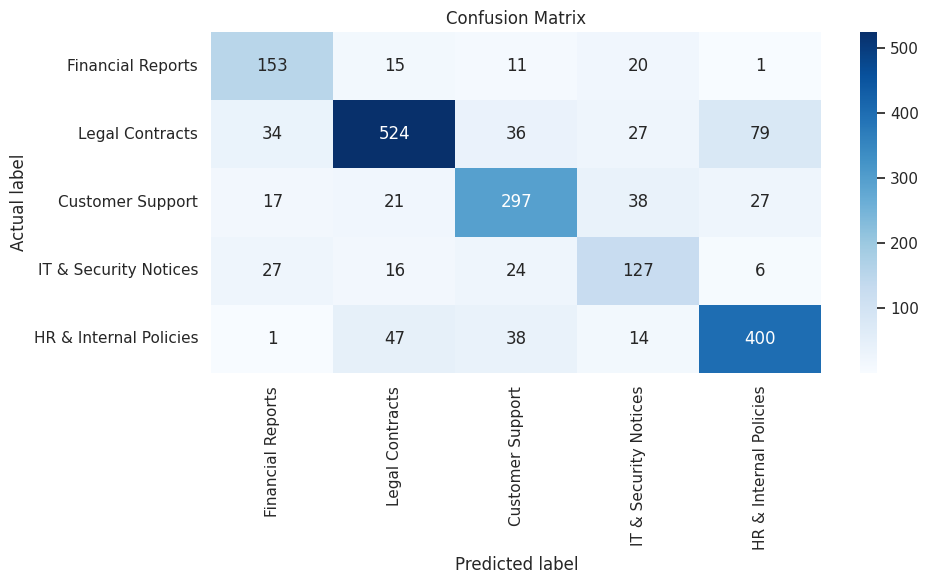

In [ ]:
# ============================================================
# MODEL EVALUATION
# ============================================================

# Generate predictions on test set
y_pred = best_model.predict(X_test)


# -----------------------------
# CLASSIFICATION REPORT
# -----------------------------

print(classification_report(y_test, y_pred, digits = 4))


# -----------------------------
# CONFUSION MATRIX
# -----------------------------

cm = confusion_matrix(y_test, y_pred, labels = best_model.classes_)

plt.figure(figsize = (10, 6))
sns.heatmap(
    cm,
    annot = True,
    fmt = 'd',
    xticklabels = labels,
    yticklabels = labels,
    cmap = 'Blues'
    )
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Confusion Matrix')

plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

### 3.2 Predizioni e inferenza

Utilizziamo ora il modello finale per fare predizioni sul set di test e paragonarle alle label effettive. Dopodiché, procederemo con l'inferenza su nuovi documenti in ingresso.

In [ ]:
# ============================================================
# COMPARISON BETWEEN PREDICTIONS AND ACTUALS
# ============================================================

test_predictions = pd.DataFrame({
    'text' : X_test.values,
    'actual_label' : y_test.values,
    'predicted_label' : y_pred
})

# Check correct and incorrect predictions
test_predictions['correct'] = (
    test_predictions['actual_label'] == test_predictions['predicted_label'])

# Check errors by label
label_stats = test_predictions.groupby('actual_label').agg(
    total_samples = ('correct', 'count'),
    correct_count = ('correct', 'sum'),
    misclassified_count = ('correct', lambda x: (~x).sum()),
    accuracy = ('correct', lambda x: round(x.mean(), 4))
).reset_index()

label_stats['error_rate (%)'] = ((1 - label_stats['accuracy']) * 100).round(2)
display(label_stats.sort_values(by = 'error_rate (%)', ascending = False))

# Show examples of errors for each label
misclassified = test_predictions[~test_predictions['correct']]
n_samples = 3

for label in sorted(test_predictions['actual_label'].unique()):
  errors_for_label = misclassified[misclassified['actual_label'] == label]

  print(f'\n\nActual label: "{label}" | Total errors: {len(errors_for_label)}')

  if len(errors_for_label) == 0:
    print('No errors for this label.')
  else:
    sample_display = errors_for_label[['text', 'predicted_label']].head(n_samples)
    display(sample_display)


,actual_label,total_samples,correct_count,misclassified_count,accuracy,error_rate (%)
3,IT & Security Notices,200,127,73,0.6350,36.50
2,HR & Internal Policies,400,297,103,0.7425,25.75
1,Financial Reports,700,524,176,0.7486,25.14
0,Customer Support,200,153,47,0.7650,23.50
4,Legal Contracts,500,400,100,0.8000,20.00




Actual label: "Customer Support" | Total errors: 47


,text,predicted_label
15,the field operations review affects activity i...,Financial Reports
19,the case will remain open until the customer-f...,HR & Internal Policies
24,one section was revised because the same term ...,IT & Security Notices




Actual label: "Financial Reports" | Total errors: 176


,text,predicted_label
10,the assessment considered exposure in context ...,Customer Support
34,the account contains operational information a...,IT & Security Notices
83,the distinction may become more important if t...,Customer Support


...

,text,predicted_label
4,the current estimate covers both the immediate...,Financial Reports
41,the technical review compared the reported seq...,IT & Security Notices
43,"the current working date is february, although...",Financial Reports




Actual label: "IT & Security Notices" | Total errors: 73


,text,predicted_label
12,the practical effect on managers and employees...,Financial Reports
17,the working assumption is that the first stage...,HR & Internal Policies
20,several points can proceed independently and t...,Customer Support




Actual label: "Legal Contracts" | Total errors: 100


,text,predicted_label
13,the account history was reviewed before decidi...,HR & Internal Policies
23,the same customer onboarding redesign has a sm...,Financial Reports
29,the account history was reviewed before decidi...,HR & Internal Policies


Ora passiamo all'inferenza. Definiamo una funzione che classifichi nuovi documenti in ingresso, dopodiché la chiamiamo su tre nuovi documenti.

In [ ]:
def classify_document(text, model):

    """
    This function classifies a new document using the trained model.
    """

    # Data cleaning
    cleaned_text = clean_text(text)

    # Obtain prediction
    prediction = model.predict([cleaned_text])[0]

    return prediction


# ============================================================
# TEST INFERENCE
# ============================================================

document_paths = [
    'document_1.txt',
    'document_2.txt',
    'document_3.txt'
]

for path in document_paths:

    with open(path, 'r', encoding = 'utf-8') as file:
        document = file.read()

    prediction = classify_document(document, best_model)

    print(f'\n--- {path} ---')
    print(document)
    print(f'\nPredicted label: {prediction}\n')


--- document_1.txt ---
The current estimate was reviewed against the prior forecast after several activities moved into a later period. The main difference appears in the monthly profile rather than in the underlying direction of the plan. The figures were therefore assessed together with expected activity, existing commitments and items that are still subject to confirmation.

The review reconciled the management summary with the supporting records and separated amounts affecting the current period from those expected to reverse in a subsequent cycle. Several movements require additional context before they can be interpreted as changes in underlying performance. An earlier version of the forecast was retained to distinguish the effect of the revised timetable from normal period-to-period variation.

The transition is expected to increase expenditure in the short term because additional work will be required to stabilise the process after implementation. The longer-term cost profile 

A giudicare dal contenuto di ciascuno dei tre testi, il modello risulta averli classificati tutti correttamente.

## 4. Conclusioni

Visualizziamo nuovamente le metriche ottenute dal test finale, per poter commentare il risultato del task di classificazione.


====================== FINAL TEST RESULTS ======================

CLASSIFICATION REPORT:

                        precision    recall  f1-score   support

      Customer Support     0.6595    0.7650    0.7083       200
     Financial Reports     0.8411    0.7486    0.7921       700
HR & Internal Policies     0.7315    0.7425    0.7370       400
 IT & Security Notices     0.5619    0.6350    0.5962       200
       Legal Contracts     0.7797    0.8000    0.7897       500

              accuracy                         0.7505      2000
             macro avg     0.7148    0.7382    0.7247      2000
          weighted avg     0.7578    0.7505    0.7525      2000


CONFUSION MATRIX:



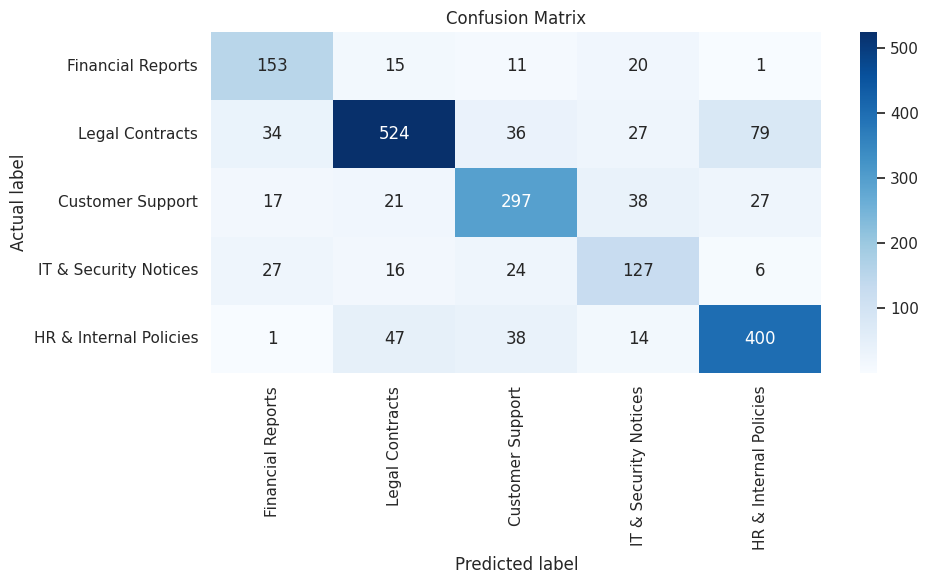

In [ ]:
print('\n====================== FINAL TEST RESULTS ======================')

print('\nCLASSIFICATION REPORT:\n')
print(classification_report(y_test, y_pred, digits = 4))

print('\nCONFUSION MATRIX:\n')
plt.figure(figsize = (10, 6))
sns.heatmap(
    cm,
    annot = True,
    fmt = 'd',
    xticklabels = labels,
    yticklabels = labels,
    cmap = 'Blues'
    )
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Confusion Matrix')

plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

Un aspetto molto positivo da evidenziare innanzitutto è che il **macro-F1** risulta leggermente più alto nel set di test rispetto al set di addestramento (0.7247 rispetto a 0.7089). Osservando anche l'**accuracy** di 0.7505 e il **weighted-F1** di 0.7525, il modello dimostra complessivamente una buona capacità di riconoscimento delle categorie di documenti aziendali. Tuttavia, è opportuno soffermarsi anche sulle metriche distinte per label indicate nel **classification report**, in quanto il modello non risulta performante alla stessa maniera per tutte le categorie.

Le classi maggiormente rappresentate nel dataset, infatti, ovvero "Financial Reports" e "Legal Contracts", ottengono delle metriche decisamente superiori rispetto alle classi che compaiono con meno frequenza, ovvero "Customer Support" e "IT & Security Notices". La metrica più alta registrata è la **precision** di "Financial Reports", con 0.8411, mentre quella più bassa è la precision di "IT & Security Notices", con 0.5619. La classe "HR & Internal Policies", invece, che è presente con una frequenza media all'interno del dataset, ottiene delle metriche in linea con la media globale.

Considerando le due classi su cui il modello è più performante, "Financial Reports" ha una precision maggiore della recall, quindi il modello si comporta meglio nell'evitare di etichettare dei falsi positivi, piuttosto che nel cercare di intercettare tutti i documenti di questa categoria ad ogni costo. Con "Legal Contracts" si presenta invece la situazione opposta.

Osservando le classi più problematiche, invece, "IT & Security Notices" ha non solo la precision molto bassa, ma anche l'F1-score, pari a 0.5962. La bassa precisione ottenuta significa che il modello identifica molti falsi positivi in questa classe, ovvero classifica in questa categoria dei documenti che invece appartengono ad altre classi. La label "Customer Support", invece, presenta una recall molto più alta della precision (0.7650 vs 0.6595), dimostrando quindi una capacità del modello di intercettare buona parte dei documenti appartenenti a questa categoria, classificando però anche molti falsi positivi.

Dalla **confusion matrix**, infine, si può notare che le categorie che vengono confuse maggiormente tra di loro sono "Legal Contracts" e "HR & Internal Policies", ma ciò è sensato poiché sono ambiti che, in un contesto aziendale, trattano spesso temi simili.

Per concludere, il modello ottiene complessivamente delle buone performance. Un eventuale punto di partenza per un miglioramento delle prestazioni potrebbe essere quello di trovare un modo per valorizzare ulteriormente le classi minoritarie del dataset, affinché le capacità di classificazione siano più uniformi tra le label.